## Setup

In [1]:
!pip install -q transformers
!pip install -q sentencepiece
!pip install -q jiwer
!pip install -q datasets
!pip install -q evaluate
!pip install -q -U accelerate

!pip install -q matplotlib
!pip install -q protobuf==3.20.1
!pip install -q tensorboard

## Imports

In [1]:
# import os
# import torch
# import evaluate
# import numpy as np
# import pandas as pd
# import glob as glob
# import torch.optim as optim
# import matplotlib.pyplot as plt
# import torchvision.transforms as transforms

# from PIL import Image
# from zipfile import ZipFile
# from tqdm.notebook import tqdm
# from dataclasses import dataclass
# from torch.utils.data import Dataset
# from urllib.request import urlretrieve
# # from transformers import (
# #     VisionEncoderDecoderModel, 
# #     TrOCRProcessor,
# #     AutoTokenizer,
# #     ViTFeatureExtractor,
# #     BertTokenizer,
# #     Seq2SeqTrainer,
# #     Seq2SeqTrainingArguments,
# #     default_data_collator
# # )

# import torch
# from torch.utils.data import Dataset, DataLoader
# from transformers import VisionEncoderDecoderModel, TrOCRConfig, VisionConfig, BertTokenizer, TrOCRProcessor, Seq2SeqTrainer, Seq2SeqTrainingArguments
# from PIL import Image
# import os

# block_plot = False
# plt.rcParams['figure.figsize'] = (12, 9)

ImportError: cannot import name 'VisionConfig' from 'transformers' (/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/__init__.py)

In [2]:
import os
import torch
import numpy as np
import pandas as pd
import glob
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

from PIL import Image
from tqdm.notebook import tqdm
from dataclasses import dataclass
from torch.utils.data import Dataset, DataLoader
from transformers import VisionEncoderDecoderModel, TrOCRConfig, ViTConfig, BertTokenizer, TrOCRProcessor, Seq2SeqTrainer, Seq2SeqTrainingArguments

# Ensure consistent plot settings
plt.rcParams['figure.figsize'] = (12, 9)

In [2]:
# Then clean the cache
torch.cuda.empty_cache()
    # then collect the garbage


In [ ]:
bold = f"\033[1m"
reset = f"\033[0m"

In [3]:
def seed_everything(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    torch.cuda.manual_seed_all(seed_value)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

In [4]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Download and Extract the Dataset

## Training and Dataset Configurations

In [5]:
@dataclass(frozen=True)
class TrainingConfig:
    BATCH_SIZE:    int = 8
    EPOCHS:        int = 10
    LEARNING_RATE: float = 0.00005

@dataclass(frozen=True)
class DatasetConfig:
    DATA_ROOT:     str = 'dataset'

@dataclass(frozen=True)
class ModelConfig:
    MODEL_NAME: str = 'microsoft/trocr-small-printed'
    # MODEL_NAME: str = "kkatiz/thai-trocr-thaigov-v2"
    
    
    VOCAB_FILE: str = 'pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt'

## The SCUT Dataset

The SCUT dataset that we are using contains a total of 7703 images. Out of these 6052 are training samples and 1651 are validation samples. Here is the directory structure of the `scut_data` directory after downloading and extracting it.

```
scut_data/
├── scut_train
├── scut_test
├── scut_train.txt
└── scut_test.txt
```

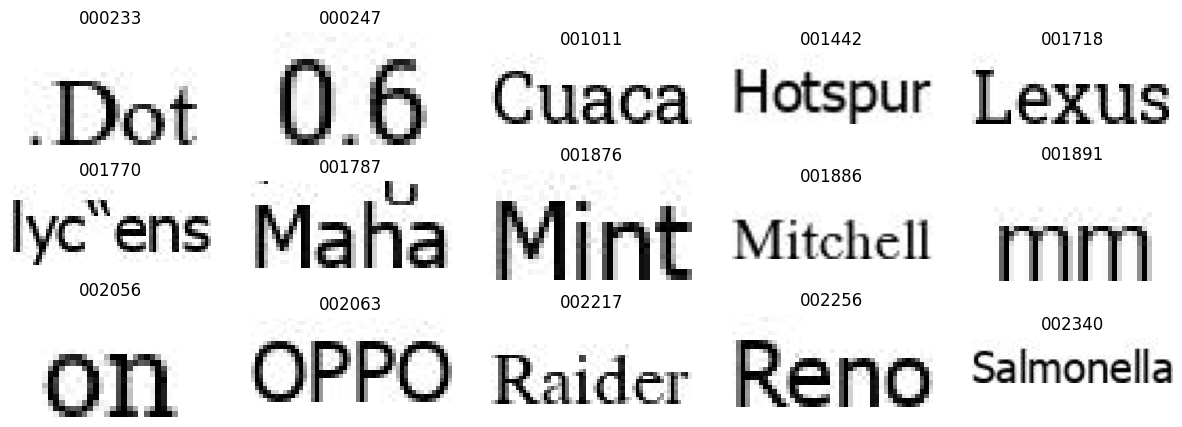

In [6]:
def visualize(dataset_path):
    plt.figure(figsize=(15, 5))
    for i in range(15):
        plt.subplot(3, 5, i+1)
        all_images = os.listdir(f"{dataset_path}/data_train")
        image = plt.imread(f"{dataset_path}/data_train/{all_images[i]}")
        plt.imshow(image)
        plt.axis('off')
        plt.title(all_images[i].split('.')[0])
    plt.show()

visualize(DatasetConfig.DATA_ROOT)

## Prepare Dataset

In [7]:
train_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_train.txt'), header=None
)
train_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)
test_df = pd.read_fwf(
    os.path.join(DatasetConfig.DATA_ROOT, 'data_test.txt'), header=None
)
test_df.rename(columns={0: 'file_name', 1: 'text'}, inplace=True)

In [8]:
train_df.head()

,file_name,text
0,000000.jpg,!(ម៉ានីល
1,000001.jpg,#១
2,000002.jpg,#២
3,000003.jpg,#៥
4,000004.jpg,$109


In [9]:
test_df.head()

,file_name,text
0,022567.jpg,!!!កាលបើ
1,022568.jpg,!Google
2,022569.jpg,$388
3,022570.jpg,$599
4,022571.jpg,(15)


In [ ]:
# # Augmentations.
# train_transforms = transforms.Compose([
#     transforms.ColorJitter(brightness=.5, hue=.3),
#     transforms.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5)),
# ])

In [ ]:
!pip install tokenizers


In [15]:
# from transformers import BertTokenizer

# # Load BERT tokenizer
# tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased", vocab_file="pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt")

# # Example Khmer text
# sample_text = "hello"

# # Tokenize the text
# tokens = tokenizer.tokenize(sample_text)

# print(f"Original text: {sample_text}")
# print(f"Tokenized text: {tokens}")


Original text: hello
Tokenized text: ['hello']


In [10]:
class CustomOCRDataset(Dataset):
    def __init__(self, root_dir, df, processor, max_target_length=128):
        self.root_dir = root_dir
        self.df = df
        self.processor = processor
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        # The image file name.
        file_name = self.df['file_name'][idx]
        # The text (label).
        text = self.df['text'][idx]
        # Read the image, apply augmentations, and get the transformed pixels.
        image = Image.open(self.root_dir + file_name).convert('RGB')
        # image = train_transforms(image)
        pixel_values = self.processor(image, return_tensors='pt').pixel_values
        # Pass the text through the tokenizer and get the labels,
        # i.e. tokenized labels.
        labels = self.processor.tokenizer(
            text,
            padding='max_length',
            max_length=self.max_target_length
        ).input_ids
        # We are using -100 as the padding token.
        labels = [label if label != self.processor.tokenizer.pad_token_id else -100 for label in labels]
        encoding = {"pixel_values": pixel_values.squeeze(), "labels": torch.tensor(labels)}
        return encoding

In [11]:
# tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased", vocab_file="pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt")


processor =TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)
# tokenizer = BertTokenizer.from_pretrained("bert-base-multilingual-cased", vocab_file="pretrained_model/bert_module_khmer/assets/vocab_file_BERT_.txt")
# feature_extractor = ViTFeatureExtractor.from_pretrained(ModelConfig.MODEL_NAME)
# processor = TrOCRProcessor(feature_extractor=feature_extractor, tokenizer=tokenizer)

train_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_train/'),
    df=train_df,
    # tokenizer = tokenizer
    processor=processor
)
valid_dataset = CustomOCRDataset(
    root_dir=os.path.join(DatasetConfig.DATA_ROOT, 'data_test/'),
    df=test_df,
    # tokenizer = tokenizer
    processor=processor
)

In [12]:
print("Number of training examples:", len(train_dataset))
print("Number of validation examples:", len(valid_dataset))

Number of training examples: 22567
Number of validation examples: 5640


In [13]:
encoding = train_dataset[0]
for k,v in encoding.items():
    print(k, v.shape)

pixel_values torch.Size([3, 384, 384])
labels torch.Size([128])


(-0.5, 75.5, 25.5, -0.5)

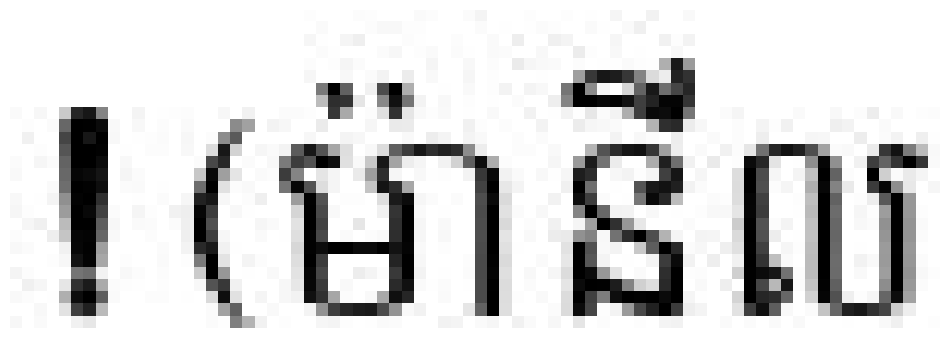

In [14]:
image = Image.open(train_dataset.root_dir + train_df['file_name'][0]).convert("RGB")
# image = train_transforms(image)
plt.imshow(image)
plt.axis('off')

In [15]:
labels = encoding['labels']
labels[labels == -100] = processor.tokenizer.pad_token_id
label_str = processor.decode(labels, skip_special_tokens=True)
print(label_str)

!(ា


## Initialize the Model

In [16]:
# model = VisionEncoderDecoderModel.from_pretrained(ModelConfig.MODEL_NAME)
model = VisionEncoderDecoderModel.from_pretrained("microsoft/trocr-base-stage1")
model.to(device)
print(model)
# Total parameters and trainable parameters.
total_params = sum(p.numel() for p in model.parameters())
print(f"{total_params:,} total parameters.")
total_trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad)
print(f"{total_trainable_params:,} training parameters.")

config.json:   0%|          | 0.00/4.21k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.54G [00:00<?, ?B/s]

Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-base-stage1 and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


generation_config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

VisionEncoderDecoderModel(
  (encoder): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=False)
              (key): Linear(in_features=768, out_features=768, bias=False)
              (value): Linear(in_features=768, out_features=768, bias=False)
              (dropout): Dropout(p=0.0, inplace=False)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_fea

## Model Configurations

In [17]:
# Set special tokens used for creating the decoder_input_ids from the labels.
model.config.decoder_start_token_id = processor.tokenizer.cls_token_id
model.config.pad_token_id = processor.tokenizer.pad_token_id
# Set Correct vocab size.
model.config.vocab_size = model.config.decoder.vocab_size
model.config.eos_token_id = processor.tokenizer.sep_token_id

model.config.max_length = 64
model.config.early_stopping = True
model.config.no_repeat_ngram_size = 3
model.config.length_penalty = 2.0
model.config.num_beams = 4

We use the AdamW optimizer here with a weight decay of 0.0005.

In [18]:
optimizer = optim.AdamW(
    model.parameters(), lr=TrainingConfig.LEARNING_RATE, weight_decay=0.0005
)

## Evaluation Metric

In [19]:
cer_metric = evaluate.load('cer')

In [27]:
# from datasets import load_metric

# cer_metric = load_metric("cer")

/tmp/ipykernel_599347/152175726.py:3: FutureWarning: load_metric is deprecated and will be removed in the next major version of datasets. Use 'evaluate.load' instead, from the new library 🤗 Evaluate: https://huggingface.co/docs/evaluate
  cer_metric = load_metric("cer")
/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/datasets/load.py:759: FutureWarning: The repository for cer contains custom code which must be executed to correctly load the metric. You can inspect the repository content at https://raw.githubusercontent.com/huggingface/datasets/2.19.2/metrics/cer/cer.py
You can avoid this message in future by passing the argument `trust_remote_code=True`.
Passing `trust_remote_code=True` will be mandatory to load this metric from the next major release of `datasets`.
  warnings.warn(


In [20]:
def compute_cer(pred):
    labels_ids = pred.label_ids
    pred_ids = pred.predictions

    pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
    labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
    label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

    cer = cer_metric.compute(predictions=pred_str, references=label_str)

    return {"cer": cer}

In [20]:
# def compute_cer(pred):
#     labels_ids = pred.label_ids
#     pred_ids = pred.predictions

#     pred_str = processor.batch_decode(pred_ids, skip_special_tokens=True)
#     labels_ids[labels_ids == -100] = processor.tokenizer.pad_token_id
#     label_str = processor.batch_decode(labels_ids, skip_special_tokens=True)

#     # Filter out empty strings
#     filtered_pred_str = []
#     filtered_label_str = []
#     for p, l in zip(pred_str, label_str):
#         if p.strip() != "" and l.strip() != "":
#             filtered_pred_str.append(p)
#             filtered_label_str.append(l)

#     cer = cer_metric.compute(predictions=filtered_pred_str, references=filtered_label_str)

#     return {"cer": cer}


## Training and Validation Loops

In [21]:
training_args = Seq2SeqTrainingArguments(
    predict_with_generate=True,
    eval_strategy='epoch',
    per_device_train_batch_size=TrainingConfig.BATCH_SIZE,
    per_device_eval_batch_size=TrainingConfig.BATCH_SIZE,
    fp16=True,
    output_dir='seq2seq_model_printed/',
    logging_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=5,
    report_to='tensorboard',
    num_train_epochs=TrainingConfig.EPOCHS
)

In [22]:
# Initialize trainer.
from transformers import default_data_collator

trainer = Seq2SeqTrainer(
    model=model,
    tokenizer=processor.tokenizer,
    args=training_args,
    compute_metrics=compute_cer,
    train_dataset=train_dataset,
    eval_dataset=valid_dataset,
    data_collator=default_data_collator
)



In [32]:
# Check batch data shapes
for batch in train_dataset:
    for k, v in batch.items():
        print(f"{k}: {v.shape}")
    break  # Print the shapes for the first batch only

pixel_values: torch.Size([3, 384, 384])
labels: torch.Size([128])


/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/models/trocr/processing_trocr.py:136: FutureWarning: `feature_extractor` is deprecated and will be removed in v5. Use `image_processor` instead.
  warnings.warn(


In [ ]:
import gc
torch.cuda.empty_cache()
gc.collect()

In [23]:
import torch
print(torch.cuda.is_available())


True


In [25]:
def training_step(model, inputs):
    # Check input shapes
    for name, input_tensor in inputs.items():
        print(f"{name} shape: {input_tensor.shape}")
    
    # Forward pass
    outputs = model(**inputs)
    
    # Check output shapes
    for name, output_tensor in outputs.items():
        print(f"{name} shape: {output_tensor.shape}")
    
    # Loss computation
    loss = outputs.loss
    return loss

try:
    res = trainer.train()
except RuntimeError as e:
    print(f"RuntimeError: {e}")


RuntimeError: CUDA error: device-side assert triggered
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1.
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.



## Train

In [23]:
res = trainer.train()

../aten/src/ATen/native/cuda/Indexing.cu:1290: indexSelectLargeIndex: block: [166,0,0], thread: [0,0,0] Assertion `srcIndex < srcSelectDimSize` failed.
../aten/src/ATen/native/cuda/Indexing.cu:1290: indexSelectLargeIndex: block: [166,0,0], thread: [1,0,0] Assertion `srcIndex < srcSelectDimSize` failed.
../aten/src/ATen/native/cuda/Indexing.cu:1290: indexSelectLargeIndex: block: [166,0,0], thread: [2,0,0] Assertion `srcIndex < srcSelectDimSize` failed.
../aten/src/ATen/native/cuda/Indexing.cu:1290: indexSelectLargeIndex: block: [166,0,0], thread: [3,0,0] Assertion `srcIndex < srcSelectDimSize` failed.
../aten/src/ATen/native/cuda/Indexing.cu:1290: indexSelectLargeIndex: block: [166,0,0], thread: [4,0,0] Assertion `srcIndex < srcSelectDimSize` failed.
../aten/src/ATen/native/cuda/Indexing.cu:1290: indexSelectLargeIndex: block: [166,0,0], thread: [5,0,0] Assertion `srcIndex < srcSelectDimSize` failed.
../aten/src/ATen/native/cuda/Indexing.cu:1290: indexSelectLargeIndex: block: [166,0,0], 

RuntimeError: Caught RuntimeError in replica 0 on device 0.
Original Traceback (most recent call last):
  File "/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/parallel/parallel_apply.py", line 83, in _worker
    output = module(*input, **kwargs)
  File "/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/modules/module.py", line 1511, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
  File "/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/modules/module.py", line 1520, in _call_impl
    return forward_call(*args, **kwargs)
  File "/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/transformers/models/vision_encoder_decoder/modeling_vision_encoder_decoder.py", line 615, in forward
    decoder_outputs = self.decoder(
  File "/home/EmHengly/.local/lib/python3.10/site-packages/torch/nn/modules/module.py", line 1511, in _wrapped_call_impl
    return self._call_impl(*args, **kwargs)
  File "/home/EmHengly/.local/lib/python3.10/s

In [25]:
res

NameError: name 'res' is not defined

## Inference

In [22]:
device = torch.device('cuda:0' if torch.cuda.is_available else 'cpu')

In [23]:
processor = TrOCRProcessor.from_pretrained(ModelConfig.MODEL_NAME)

# Specify the checkpoint path
checkpoint_path = 'seq2seq_model_printed-1/checkpoint-7065'

# Load the model from the checkpoint
trained_model = VisionEncoderDecoderModel.from_pretrained(checkpoint_path).to(device)

# trained_model = VisionEncoderDecoderModel.from_pretrained('seq2seq_model_printed/checkpoint-'+str(res.global_step)).to(device)

In [24]:
def read_and_show(image_path):
    """
    :param image_path: String, path to the input image.

    Returns:
        image: PIL Image.
    """
    image = Image.open(image_path).convert('RGB')
    return image

In [25]:
def ocr(image, processor, model):
    """
    :param image: PIL Image.
    :param processor: Huggingface OCR processor.
    :param model: Huggingface OCR model.

    Returns:
        generated_text: the OCR'd text string.
    """
    # We can directly perform OCR on cropped images.
    pixel_values = processor(image, return_tensors='pt').pixel_values.to(device)
    generated_ids = model.generate(pixel_values)
    generated_text = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
    return generated_text

In [26]:
# def eval_new_data(
#     data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
#     num_samples=50
# ):
#     image_paths = glob.glob(data_path)
#     for i, image_path in tqdm(enumerate(image_paths), total=len(image_paths)):
#         if i == num_samples:
#             break
#         image = read_and_show(image_path)
#         text = ocr(image, processor, trained_model)
#         plt.figure(figsize=(7, 4))
#         plt.imshow(image)
#         plt.title(text)
#         plt.axis('off')
#         plt.show()

In [ ]:
# def eval_new_data(data_path=os.path.join(DATA_ROOT, 'data_test', '*'), num_samples=50):
#     image_paths = glob.glob(data_path)
#     for i, image_path in tqdm(enumerate(image_paths), total=len(image_paths)):
#         if i == num_samples:
#             break
#         image = read_and_show(image_path)
#         text = ocr(image, processor, trained_model)
        
#         # Display the image and the OCR result
#         plt.figure(figsize=(7, 4))
#         plt.imshow(image)
#         plt.title(text, fontname="Khmer OS System", fontsize=12)  # Ensure Khmer font is available
#         plt.axis('off')
#         plt.show()

In [ ]:
def eval_new_data(data_path=os.path.join(DATA_ROOT, 'data_test', '*'), num_samples=50):
    image_paths = glob.glob(data_path)
    for i, image_path in tqdm(enumerate(image_paths), total=len(image_paths)):
        if i == num_samples:
            break
        image = read_and_show(image_path)
        text = ocr(image, processor, trained_model)
        
        # Display the image and the OCR result
        plt.figure(figsize=(7, 4))
        plt.imshow(image)
        plt.title(text, fontname="Khmer OS System", fontsize=12)  # Ensure Khmer font is available
        plt.axis('off')
        plt.show()

In [39]:
pip install ipywidgets


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.4/139.4 kB 3.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.4/214.4 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 11.9 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


  0%|          | 0/5640 [00:00<?, ?it/s]

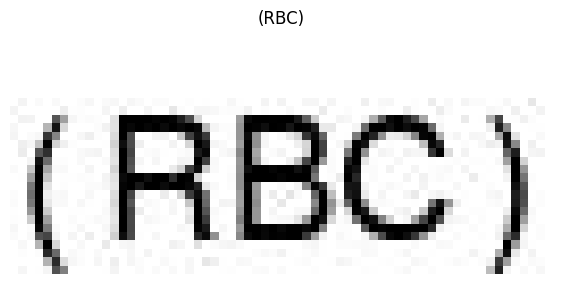

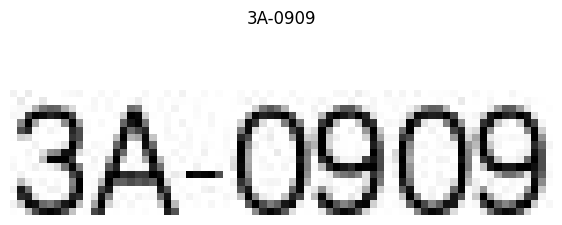

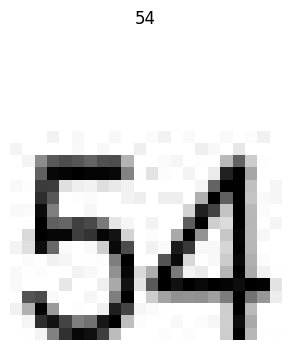

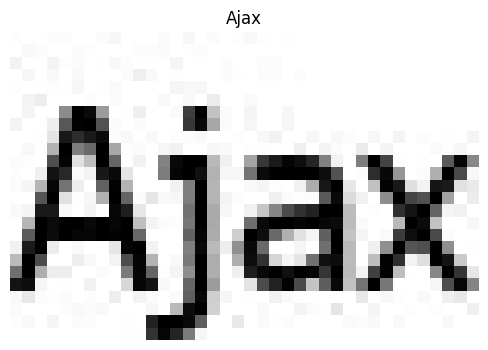

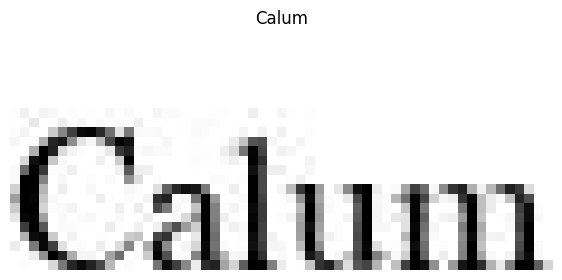

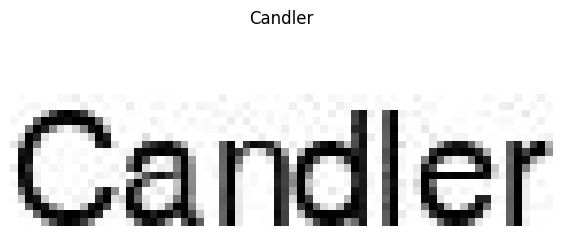

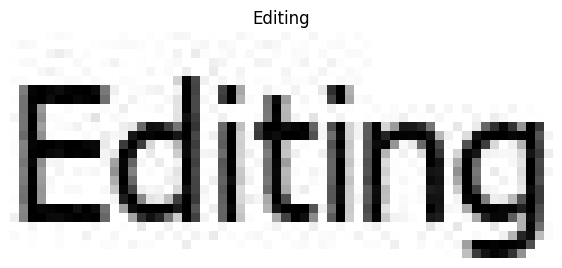

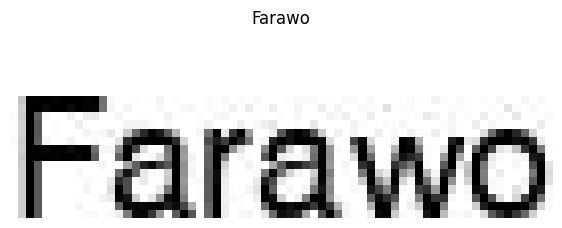

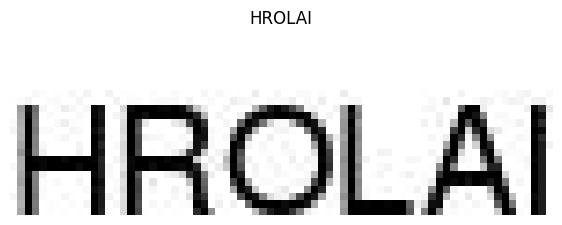

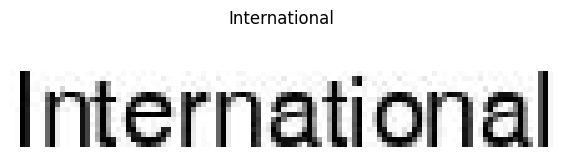

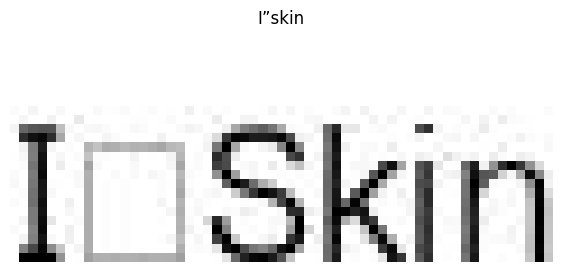

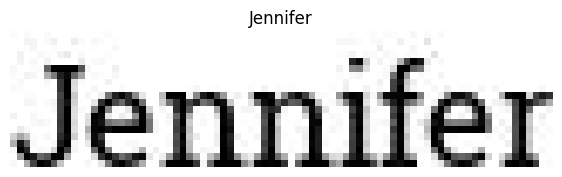

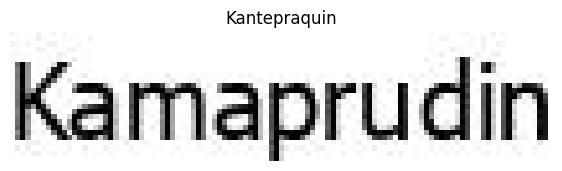

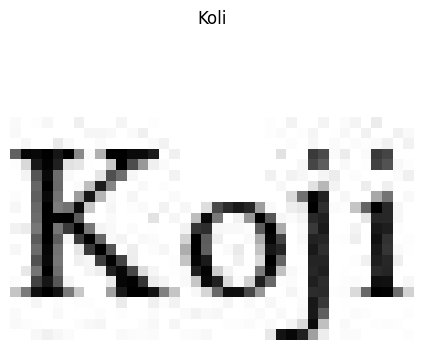

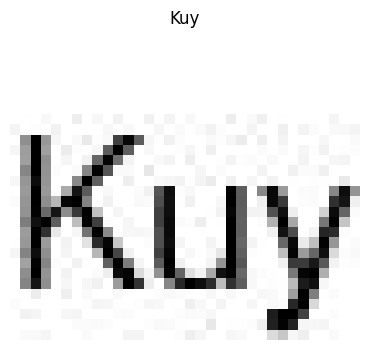

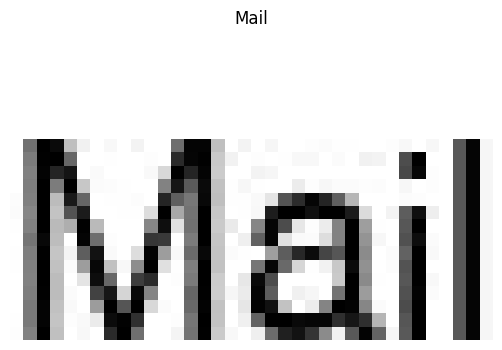

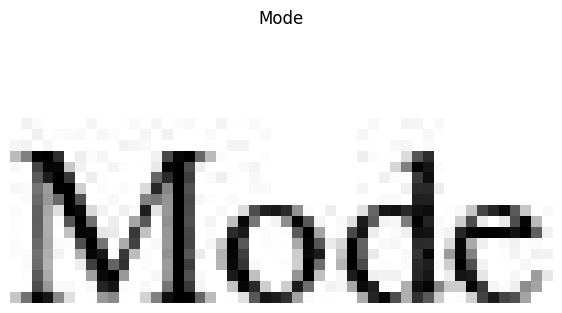

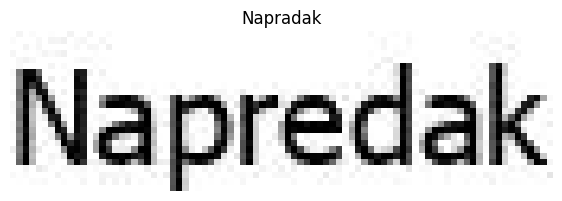

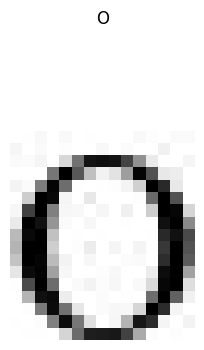

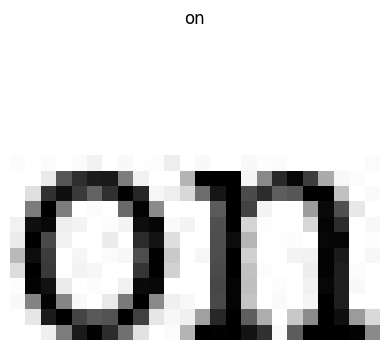

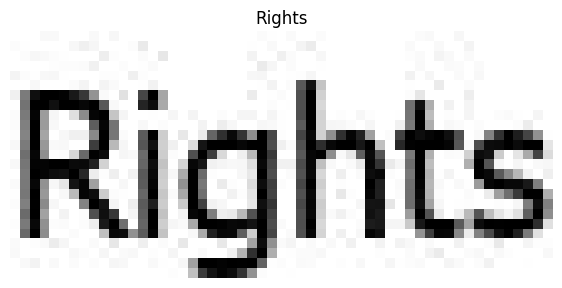

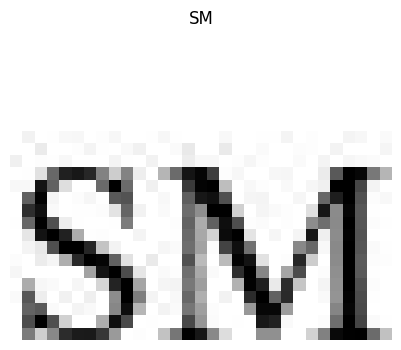

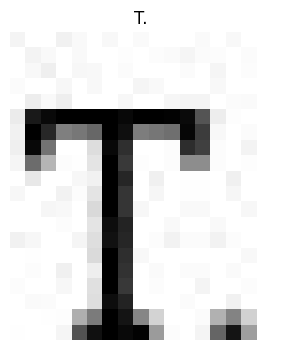

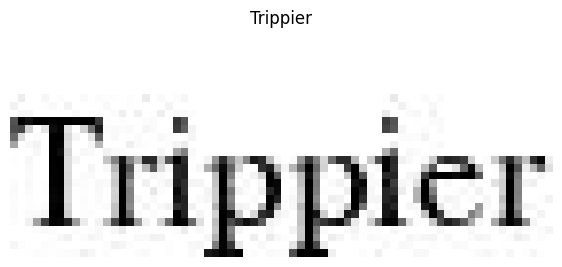

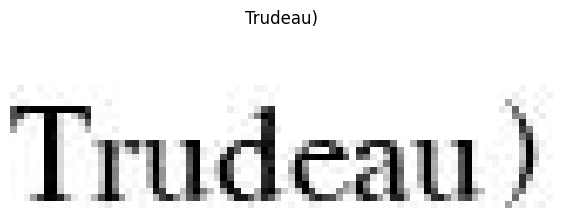

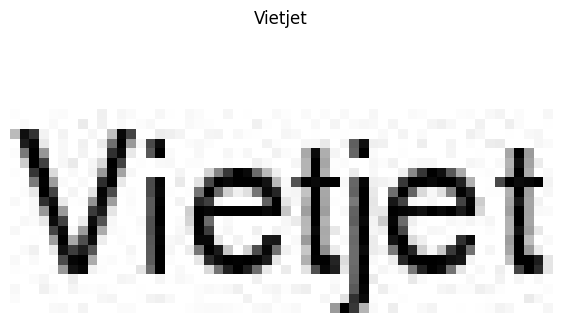

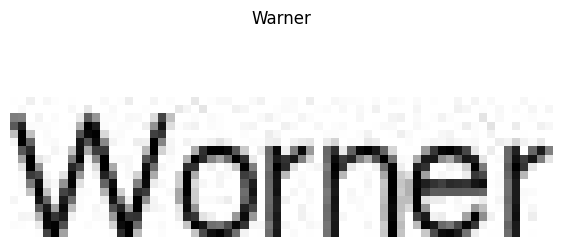

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 6070 (\N{KHMER VOWEL SIGN AA}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


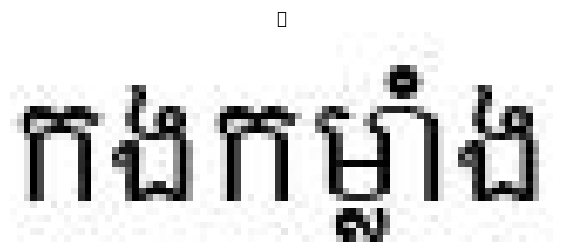

/home/EmHengly/miniconda3/envs/khocr/lib/python3.10/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 6098 (\N{KHMER SIGN COENG}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


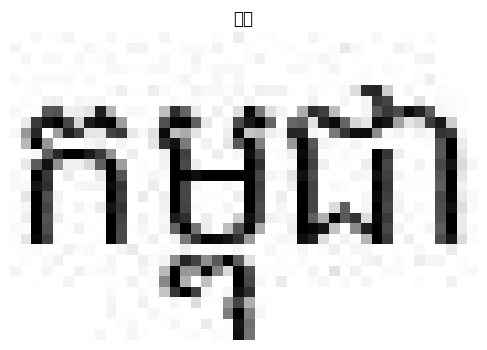

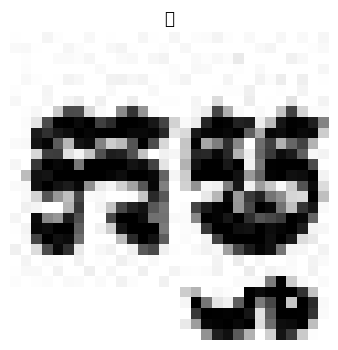

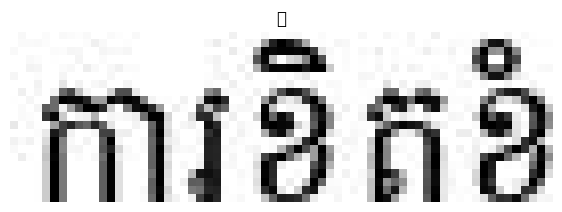

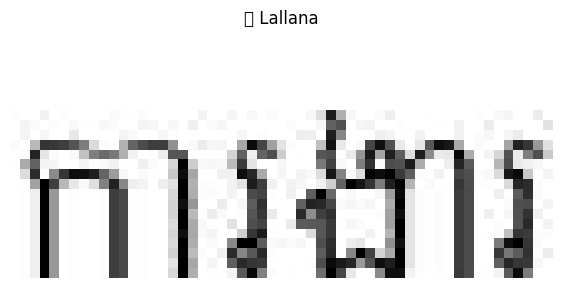

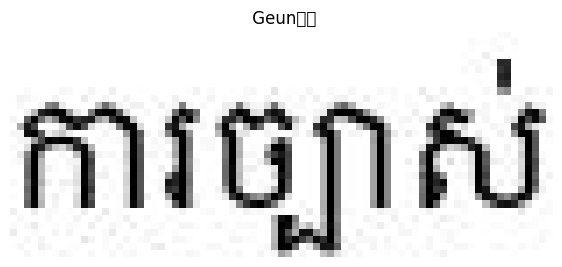

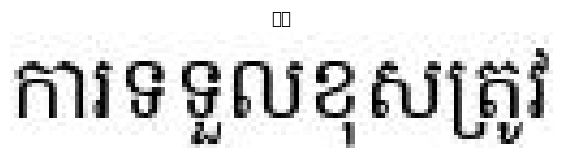

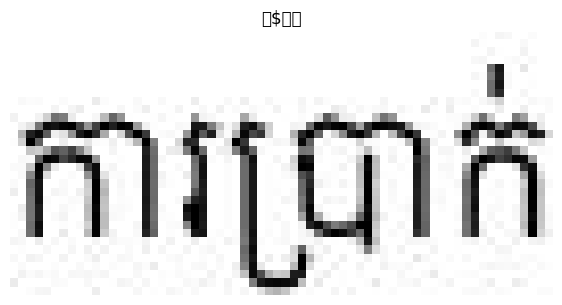

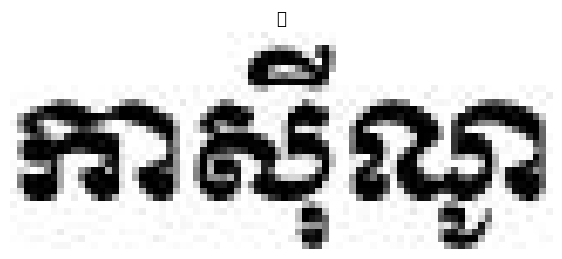

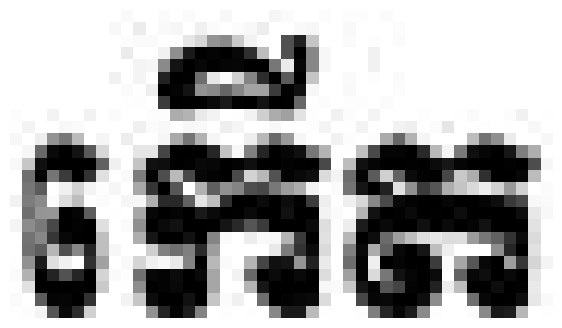

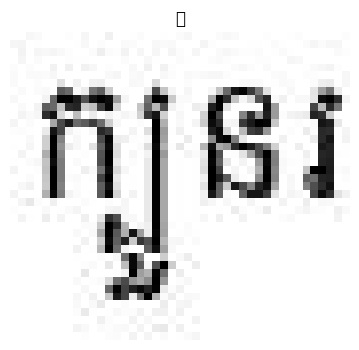

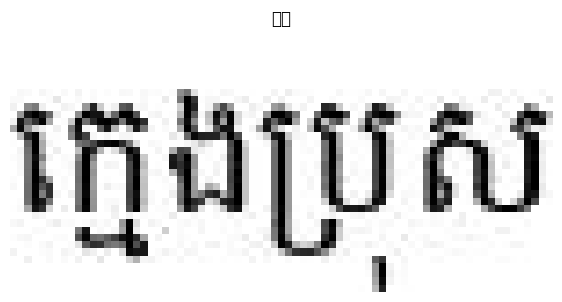

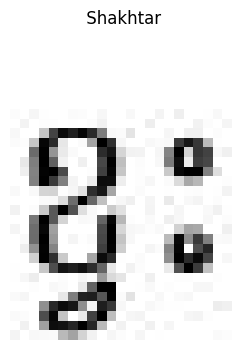

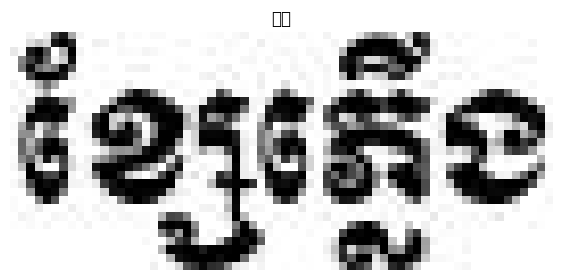

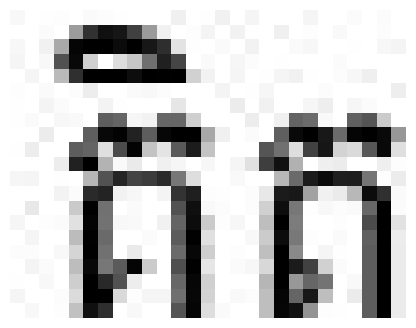

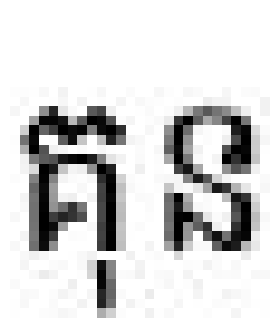

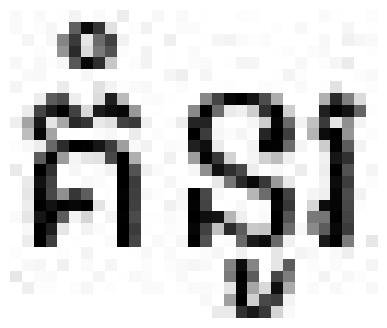

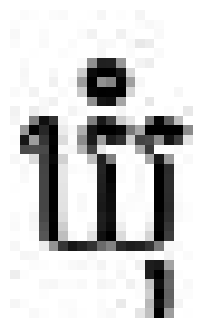

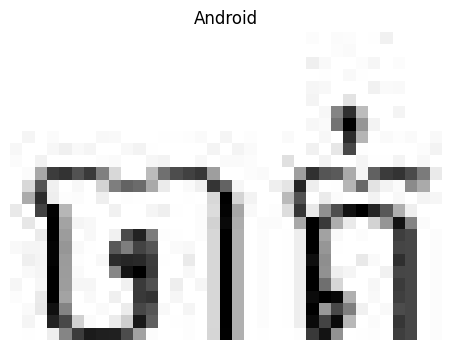

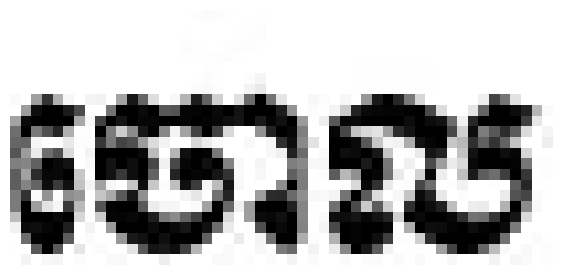

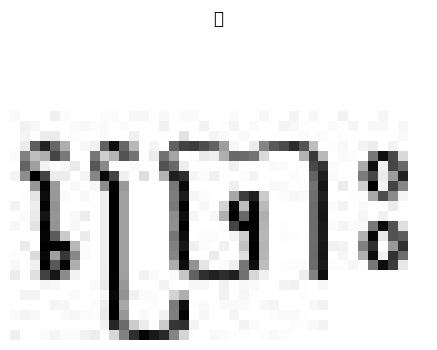

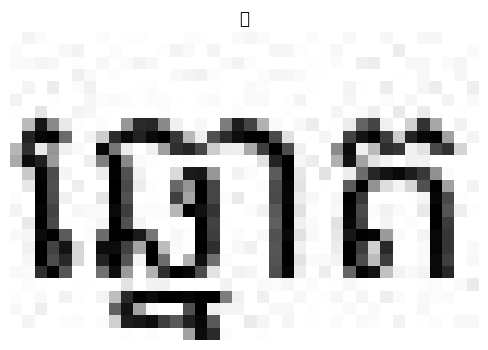

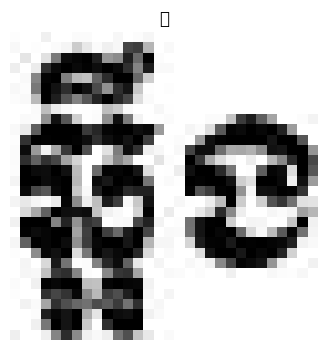

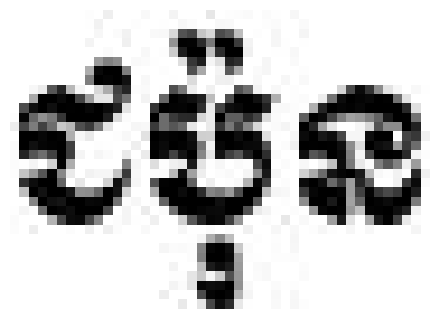

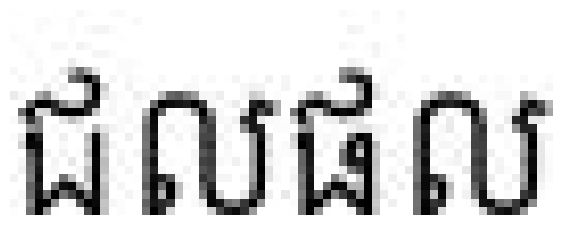

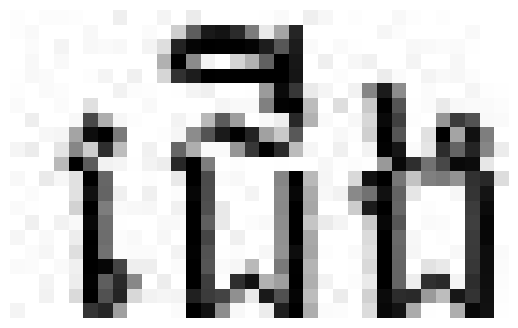

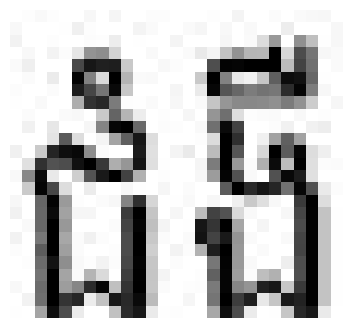

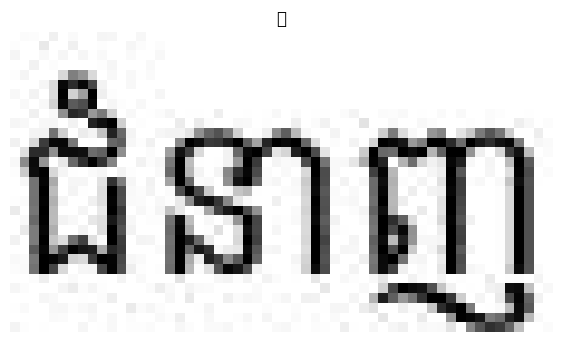

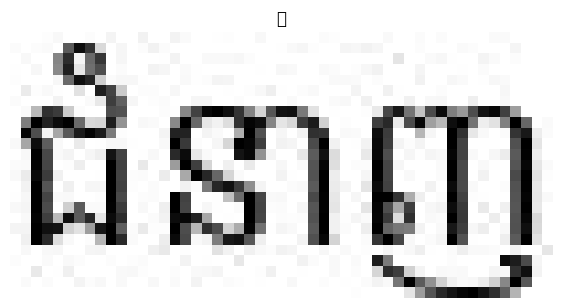

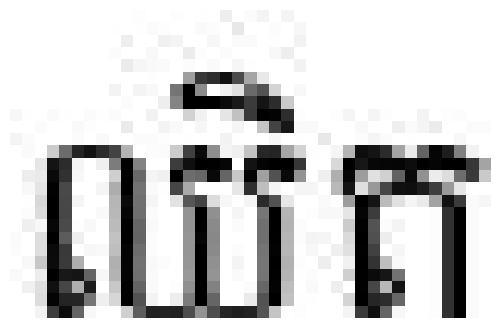

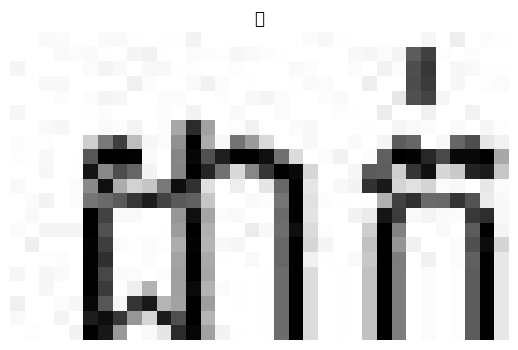

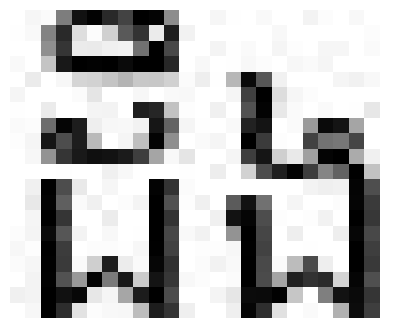

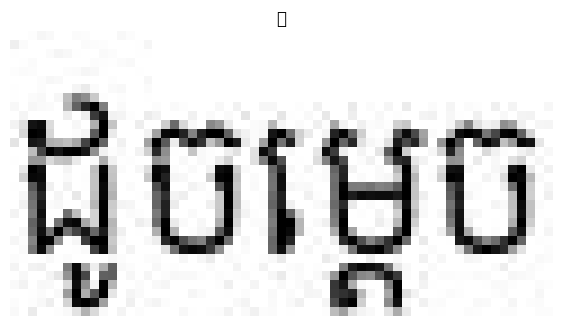

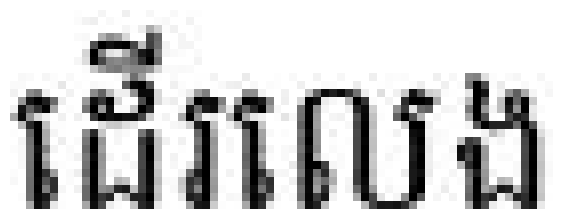

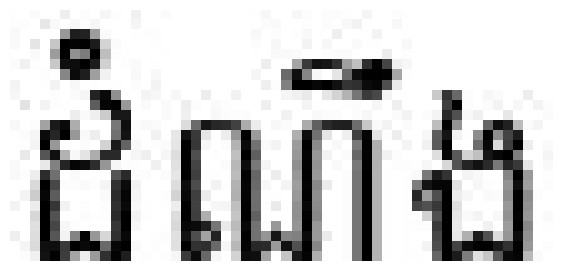

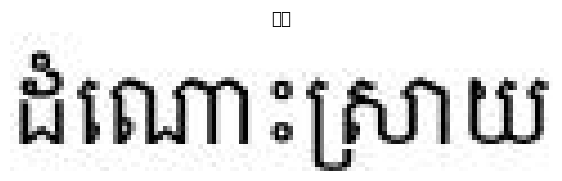

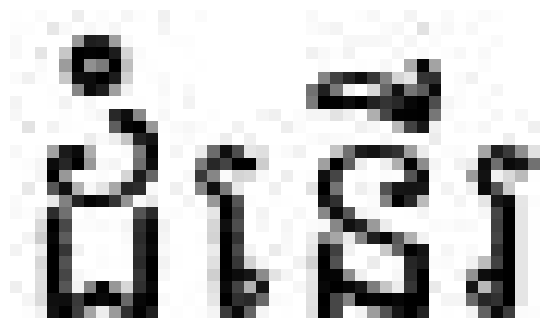

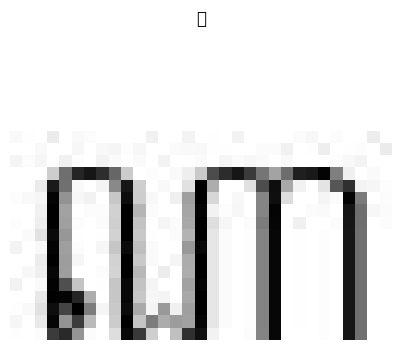

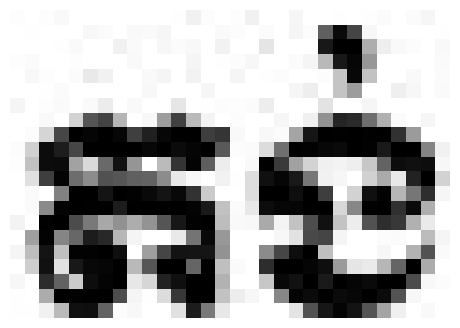

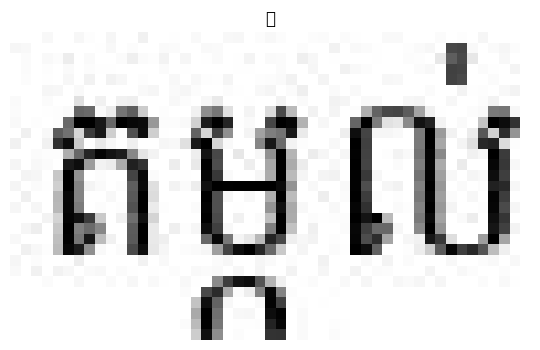

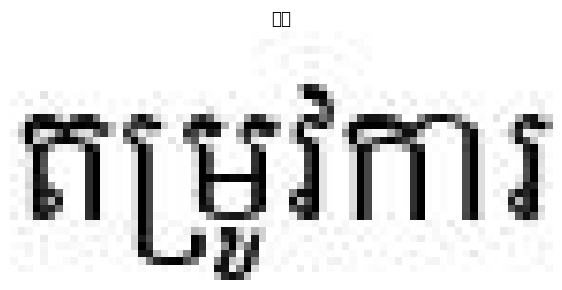

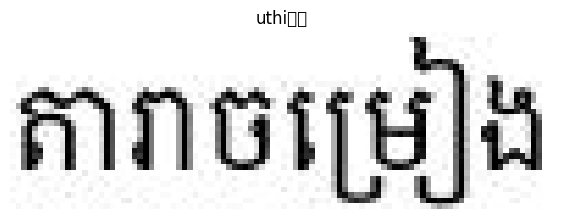

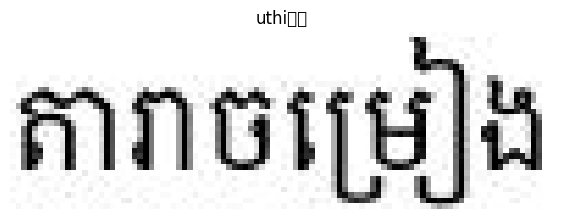

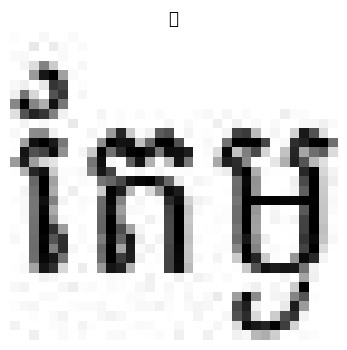

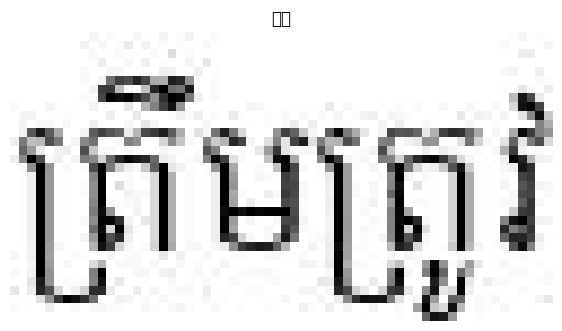

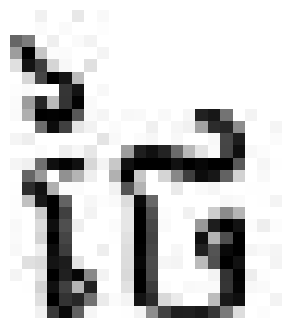

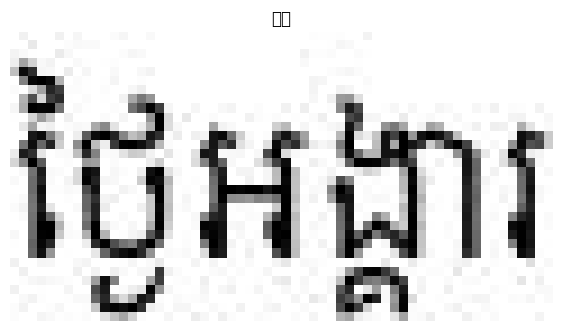

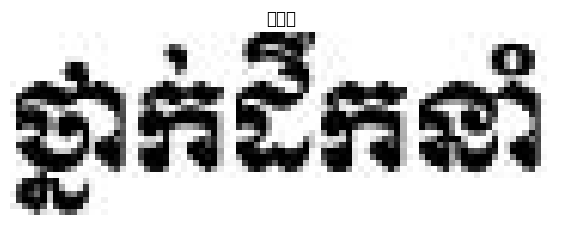

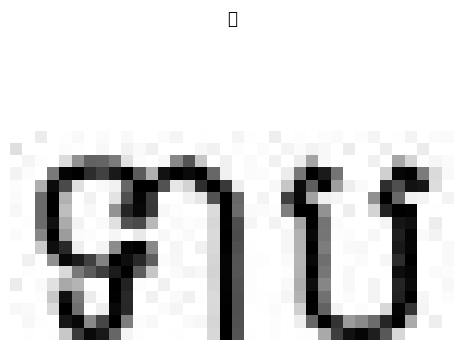

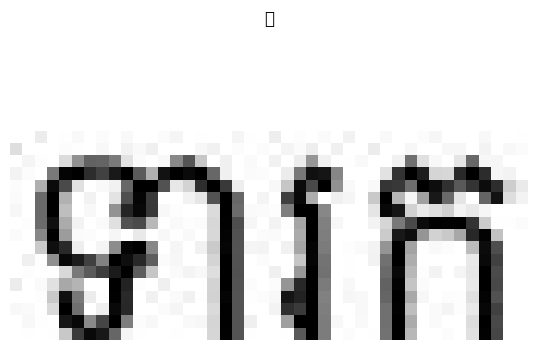

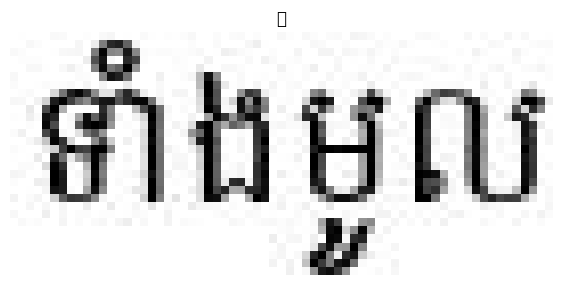

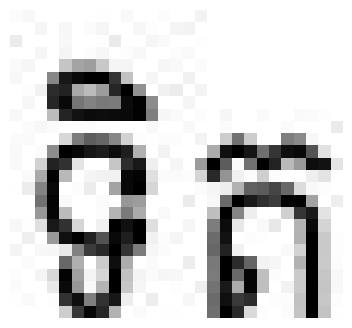

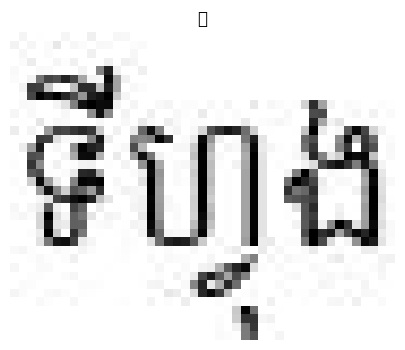

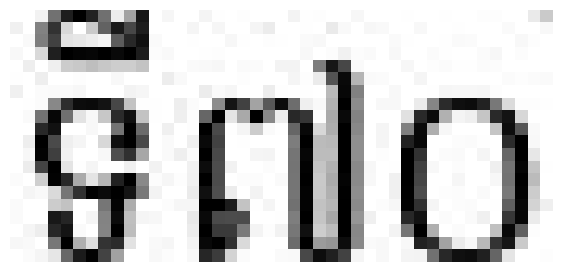

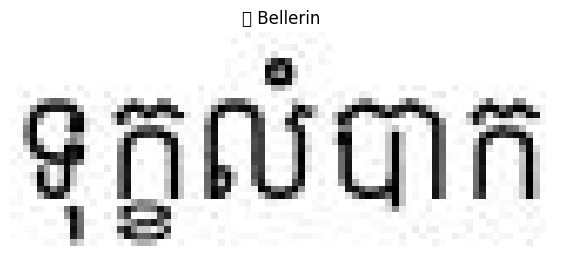

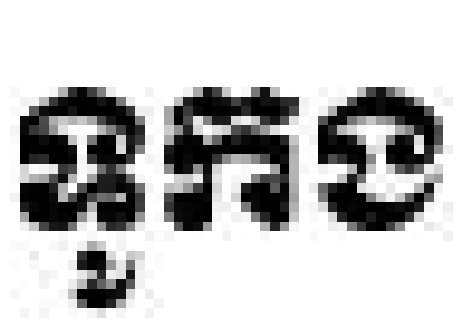

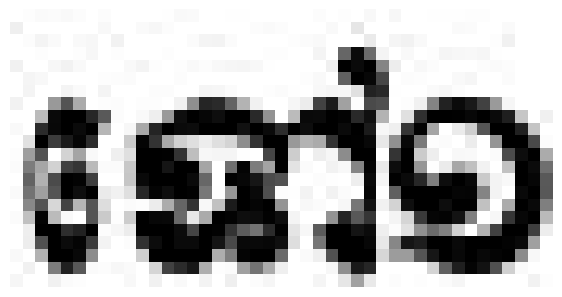

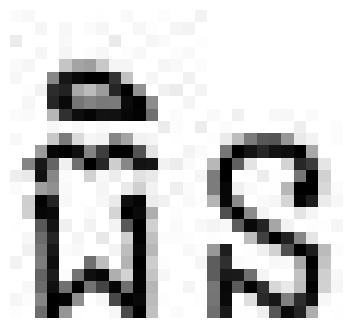

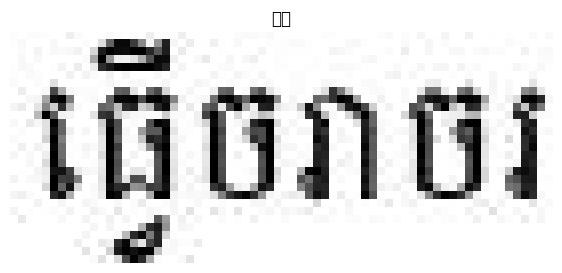

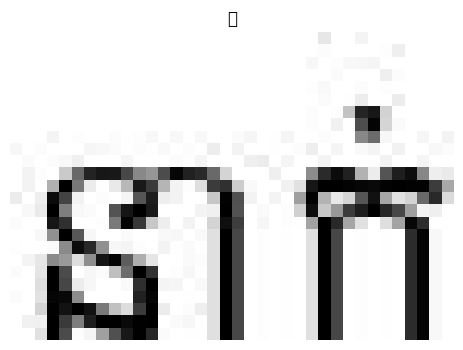

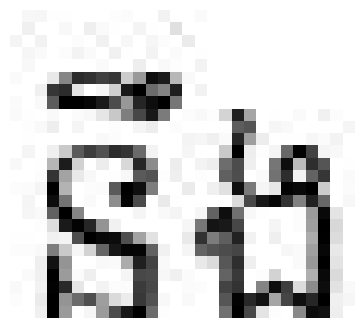

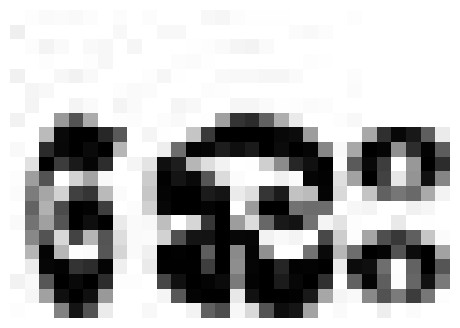

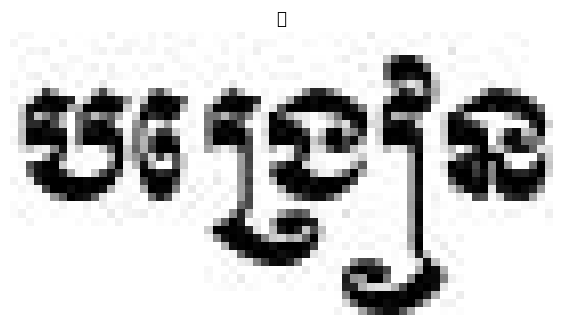

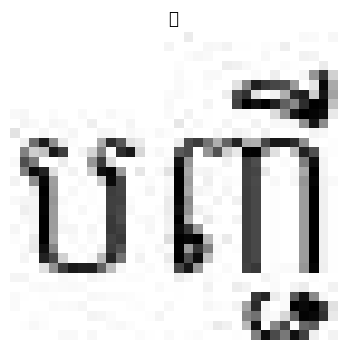

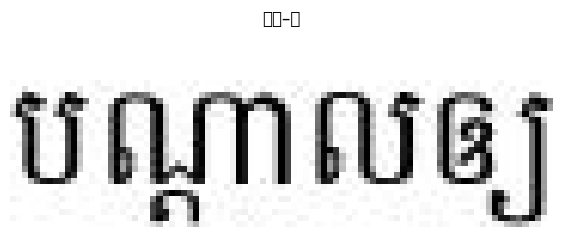

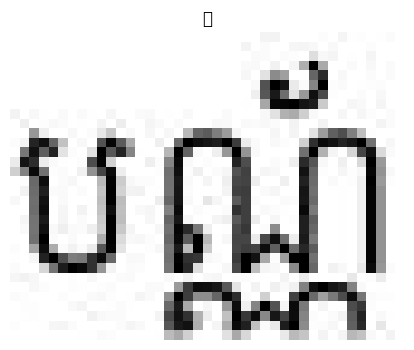

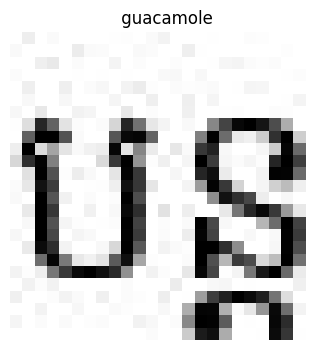

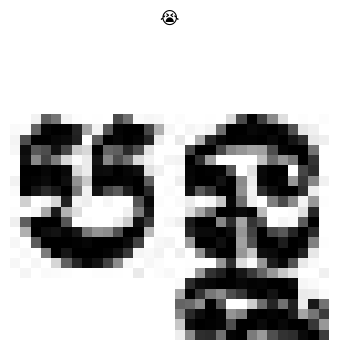

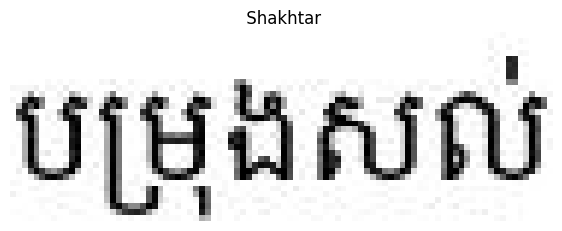

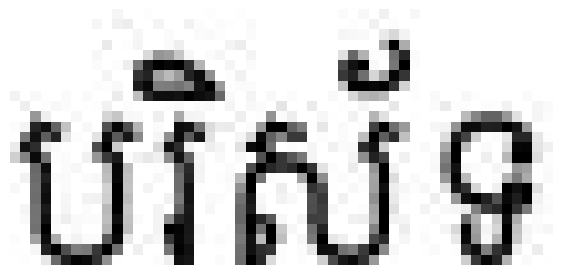

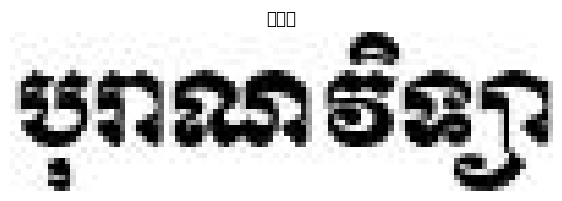

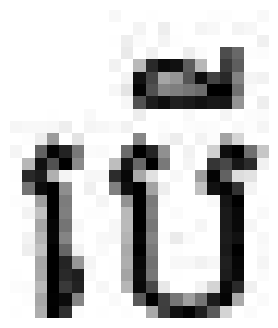

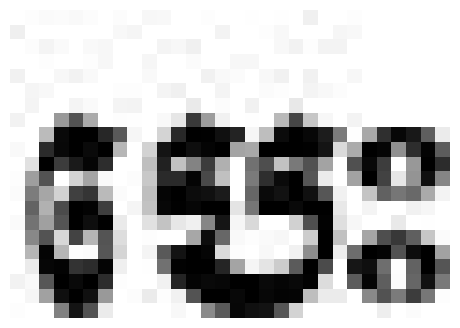

In [27]:
eval_new_data(
    data_path=os.path.join(DatasetConfig.DATA_ROOT, 'data_test', '*'),
    num_samples=100
)

In [41]:
!pip install --upgrade jupyter ipywidgets


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


  Using cached jupyter-1.0.0-py2.py3-none-any.whl.metadata (995 bytes)
  Using cached jupyter_console-6.6.3-py3-none-any.whl.metadata (5.8 kB)
  Using cached beautifulsoup4-4.12.3-py3-none-any.whl.metadata (3.8 kB)
  Using cached bleach-6.1.0-py3-none-any.whl.metadata (30 kB)
  Using cached jupyterlab_pygments-0.3.0-py3-none-any.whl.metadata (4.4 kB)
  Using cached mistune-3.0.2-py3-none-any.whl.metadata (1.7 kB)
  Using cached nbclient-0.10.0-py3-none-any.whl.metadata (7.8 kB)
  Using cached nbformat-5.10.4-py3-none-any.whl.metadata (3.6 kB)
  Using cached pandocfilters-1.5.1-py2.py3-none-any.whl.metadata (9.0 kB)
  Using cached notebook_shim-0.2.4-py3-none-any.whl.metadata (4.0 kB)
  Using cached QtPy-2.4.1-py3-none-any.whl.metadata (12 kB)
  Using cached argon2_cffi-23.1.0-py3-none-any.whl.metadata (5.2 kB)
  Using cached jupyter_events-0.10.0-py3-none-any.whl.metadata (5.9 kB)
  Using cached jupyter_server_terminals-0.5.3-py3-none-any.whl.metadata (5.6 kB)
  Using cached overrides-